## Agrupamento - K-Means e Aplicações

---

Essa primeira apresentação do método e a construção do dataset é baseada no material de David Sheehan.

In [16]:
import pandas as pd
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split

# Models
#from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

# Feature Selection
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, cross_val_score, ShuffleSplit

# Auxiliary Scores
from sklearn.metrics import recall_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import log_loss
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings(action='ignore')

In [9]:
import pandas as pd
df = pd.read_csv('classificacao_1.csv')

In [10]:
df.head()

,v_1,v_2,v_3,v_4,v_5,v_6,v_7,v_8,v_9,v_10,v_11,v_12,v_13,v_14,v_15,v_16,v_17,v_18,target
0,-0.79207,-1.53485,0.60615,-2.27976,-1.43551,2.44272,-1.18421,1.83623,-2.79111,0.38763,-2.84928,-1.45238,-3.43264,-0.70667,-0.71361,-2.32598,-2.71869,-1.76932,0
1,0.21583,-0.93657,0.75756,0.37746,-2.60988,1.85922,2.62460,0.24354,-3.43729,-0.26536,1.34649,-1.45203,3.12942,2.18204,-0.95989,-2.69853,4.91233,0.09381,0
2,-0.32059,-2.16565,-1.63757,0.79361,-1.95570,-0.18525,-0.88095,-0.98657,-4.14707,1.61340,-0.68718,-1.17566,-0.04852,1.20091,1.55407,-3.31448,0.24915,3.10828,0
3,-0.12929,-0.06134,3.58236,-1.48172,1.41317,-1.47032,-1.05289,1.87866,-1.99177,1.13534,0.49201,-0.21985,-1.43865,-0.64562,-0.28754,3.76759,-3.87927,-0.74953,0
4,-1.85108,-3.65335,0.10311,-0.18259,-1.71422,1.21289,-2.22696,-1.53030,-2.15125,0.77353,-2.36629,-1.76121,-5.21324,-0.88661,-0.24870,0.90993,-0.10623,-1.38851,0


In [21]:
np.mean([6, 12, 8, 11, 14, 1, 13, 15, 5, 10, 16, 12])

10.25

In [14]:
data = df.drop('target',axis=1)
target = df.target

In [15]:
# separando os dados em treino e teste
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(data, target, test_size=0.33, random_state=42)

In [18]:
# utilizando validação cruzada com KFold #não tem extratificação
from sklearn.model_selection import KFold
kf = KFold(n_splits = 10)#paraceido com shuffle split

acc = []
for train_index, test_index in kf.split(data):
    knn = KNeighborsClassifier(n_neighbors = 1)
    knn.fit(data[train_index],target[train_index])#treino
    y_pred = knn.predict(data[test_index])
    acc.append(accuracy_score(y_pred,target[test_index]))

acc = np.asarray(acc) # converte pra numpy pra ficar mais simples de usar média e desvio padrão
print('Accuracy - %.2f +- %.2f' % (acc.mean() * 100, acc.std() * 100))
print(f'Baseline - Regressão Logistica')
print('---')
print(f'Acurácia: {round(accuracy, 6)}%')
print(f'Recall: {round(recall, 6)}%')
#print(f'Precisão: {round(precision, 6)}%')
#print(f'Log Loss: {round(logloss, 6)}')
print(f'F1 Score: {round(f1, 6)}')


print('---')
print('Matriz de Confusão')
display(pd.DataFrame(confusion_matrix(y_test, y_pred_class)))
print('---')

KeyError: '[ 125  126  127 ... 1247 1248 1249] not in index'

In [ ]:
def gridSearchSVC(X_Train, y_Train, X_Val, y_Val):
    svc=SVC()
    param_grid = [{'kernel': ['linear'], 'C': [1]}]
    scores = ['f1']
    for sc in scores:
        grid=GridSearchCV(svc,param_grid,cv=4,scoring=sc,n_jobs=-1)
        
        print("Support Vector Classifier - Tuning hyper-parameters for %s" % sc)
        
        grid.fit(X_Train,y_Train)
        print(grid.best_params_)
        print(np.round(grid.best_score_,3))
        
        y_pred_class = grid.predict(X_Val)

        recall = recall_score(y_Val, y_pred_class)
        accuracy = accuracy_score(y_Val, y_pred_class)
        gini = eval_gini(y_Val, y_pred_class)
        precision =  precision_score(y_Val, y_pred_class)
        f1 = f1_score(y_Val, y_pred_class)

        print(f'SVC with recall-maxing hyperparameters - {grid.best_params_}')
        print('---')
        print(f'Acurácia: {round(accuracy, 6)}%')
        print(f'Recall: {round(recall, 6)}%')
        print(f'Precisão: {round(precision, 6)}%')
        print(f'F1 Score: {round(f1, 6)}')
        print(f'Gini: {round(gini, 6)}')

        print('---')
        print('Matriz de Confusão')
        display(pd.DataFrame(confusion_matrix(y_Val, y_pred_class)))
        print('---')
        
        return grid, f'SVC with recall-maxing hyperparameters - {grid.best_params_}'

Uma forma de associar os pontos aos grupos é com o algoritmo K-Means, o qual inicia pontos aleatórios e depois associa os pontos em um processo repetitivo, até que a movimentação entre os pontos e os centros seja pequena ou nenhuma.
No entanto, é possível perceber que para certas estruturas, o K-Means não tem desempenho satisfatório. Especificamente, o K-Means é muito útil para estruturas globulares.

Dataset1
Cluster 0: 1002
Cluster 1: 1000
Cluster 2: 995
Cluster 3: 1003


TypeError: unhashable type: 'slice'

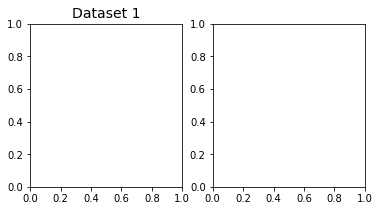

In [5]:
# implementing k-means clustering
import pandas as pd
dataset1 = pd.read_csv('agrupamento.csv')
kmeans_dataset1 = cluster.KMeans(n_clusters=4, max_iter=300, 
                                 init='k-means++',n_init=10).fit_predict(dataset1)
kmeans_dataset2 = cluster.KMeans(n_clusters=2, max_iter=300, 
                                 init='k-means++',n_init=10).fit_predict(dataset2)
print('Dataset1')
print(*["Cluster "+str(i)+": "+ str(sum(kmeans_dataset1==i)) for i in range(4)], sep='\n')
cluster_plots(dataset1, dataset2, kmeans_dataset1, kmeans_dataset2)

# implementing k-means clustering
import pandas as pd
pd.load_csv('agrupamento.csv')
kmeans_dataset1 = cluster.KMeans(n_clusters=4, max_iter=300, 
                                 init='k-means++',n_init=10).fit_predict(dataset1)
kmeans_dataset2 = cluster.KMeans(n_clusters=2, max_iter=300, 
                                 init='k-means++',n_init=10).fit_predict(dataset2)
print('Dataset1')
print(*["Cluster "+str(i)+": "+ str(sum(kmeans_dataset1==i)) for i in range(4)], sep='\n')
cluster_plots(dataset1, dataset2, kmeans_dataset1, kmeans_dataset2)

In [ ]:
kmeans_dataset1 = cluster.KMeans(n_clusters=4, max_iter=300, 
                                 init='k-means++',n_init=10).fit_predict(np.vstack([dataset1[:2080,:],
                                                                                    dataset1[3000:3080,:]]))
kmeans_dataset2 = cluster.KMeans(n_clusters=4, max_iter=300, 
                                 init='k-means++',n_init=10).fit_predict(np.vstack([dataset1[-2080:,],
                                                                                    dataset1[:80,]]))
cluster_plots(np.vstack([dataset1[:2080,],dataset1[3000:3080,]]), 
              np.vstack([dataset1[-2080:,],dataset1[:80,]]), 
              kmeans_dataset1, kmeans_dataset2,title1='', title2='')

In [ ]:
hc_dataset1 = cluster.AgglomerativeClustering(n_clusters=4, affinity='euclidean', 
                                              linkage='ward').fit_predict(dataset1)
hc_dataset2 = cluster.AgglomerativeClustering(n_clusters=2, affinity='euclidean', 
                                              linkage='average').fit_predict(dataset2)
print("Dataset 1")
print(*["Cluster "+str(i)+": "+ str(sum(hc_dataset1==i)) for i in range(4)], sep='\n')
cluster_plots(dataset1, dataset2, hc_dataset1, hc_dataset2)

In [ ]:
hc_dataset2 = cluster.AgglomerativeClustering(n_clusters=2, affinity='euclidean', 
                                              linkage='complete').fit_predict(dataset2)
connect = kneighbors_graph(dataset2, n_neighbors=5, include_self=False)
hc_dataset2_connectivity = cluster.AgglomerativeClustering(n_clusters=2, affinity='euclidean', 
                                              linkage='complete',connectivity=connect).fit_predict(dataset2)
cluster_plots(dataset2, dataset2,hc_dataset2,hc_dataset2_connectivity,
             title1='Without Connectivity', title2='With Connectivity')

Outras técnicas e outras dificuldades dos conjuntos de dados podem ser observados nesse artigo mais completo, de onde essa parte do material foi retirada: https://dashee87.github.io/data%20science/general/Clustering-with-Scikit-with-GIFs/

---

### Classificação utilizando o K-Means

A classificação utilizando o K-Means implica em representar uma amostra pela distância dela para todos os centros de grupos no espaço vetorial. Desse modo, a quantidade de atributos dá amostra passa a ser a distância da amostra para cada centro configurado no modelo do K-Means.

In [1]:
from sklearn.datasets import load_digits, load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans

def clust(dataset_load, n_clusters):

    ds = dataset_load()
    X = ds.data
    y = ds.target

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2019)

    model = LogisticRegression(random_state=42)
    model.fit(X_train, y_train)
    print('Sem clustering:', model.score(X_test, y_test))

    km = KMeans(n_clusters = n_clusters, random_state=42)
    X_train = km.fit_transform(X_train)
    X_test  = km.transform(X_test)

    model = LogisticRegression(random_state=42)
    model.fit(X_train, y_train)
    print('Com clustering:', model.score(X_test, y_test))
    

print('Digits dataset')
clust('agrupamento.csv', n_clusters = 3)
print()
print('Iris dataset')
clust(load_iris, n_clusters = 3)


Digits dataset


TypeError: 'str' object is not callable

---

### Quantização de cores com K-Means

E se fosse possível agrupar os tons de cores, e recolorir uma imagem apenas utilizando as centróides do K-Means, em vez de todos os tons de cores? Esse exemplo é baseado no material da documentação do Scikit-Learn: https://scikit-learn.org/stable/auto_examples/cluster/plot_color_quantization.html

Se o exemplo não funcionar nas máquinas do laboratório, tente executar em sua casa após instalar a biblioteca PIL.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances_argmin
from sklearn.datasets import load_sample_image
from sklearn.utils import shuffle

n_colors = 64 # varie o numero de cores

china = load_sample_image("china.jpg") # tente como flower.jpg tambem

# normaliza entre 0 e 1 pro plt não ter problema
china = np.array(china, dtype=np.float64) / 255

w, h, d = original_shape = tuple(china.shape)
image_array = np.reshape(china, (w * h, d))

image_array_sample = shuffle(image_array, random_state=0)[:1000]
kmeans = KMeans(n_clusters=n_colors, random_state=0).fit(image_array_sample)

labels = kmeans.predict(image_array)

def recreate_image(codebook, labels, w, h):
    d = codebook.shape[1]
    image = np.zeros((w, h, d))
    label_idx = 0
    for i in range(w):
        for j in range(h):
            image[i][j] = codebook[labels[label_idx]]
            label_idx += 1
    return image

plt.figure(1)
plt.clf()
plt.axis('off')
plt.title('Original image (96,615 colors)')
plt.imshow(china)

plt.figure(2)
plt.clf()
plt.axis('off')
plt.title('Quantized image (64 colors, K-Means)')
plt.imshow(recreate_image(kmeans.cluster_centers_, labels, w, h))